In [1]:
import sys
print(sys.executable)


c:\Users\asad\miniconda3\envs\ydata_profiling\python.exe


In [2]:
import sys
!{sys.executable} -m pip install plotly kaleido scikit-learn imageio pillow matplotlib nbformat

# NYC Taxi Data Analysis – Advanced Data Preprocessing and Visualization
**Project 3 | Data Preprocessing, NumPy & Advanced Visualization**

In this notebook we take the raw NYC taxi trip data, clean it, build new features, scale and encode it,
work with NumPy arrays, and finish with interactive Plotly charts (geo map, animation, sunburst and a GIF).

**Before you run it**
1. Download `train.csv` from Kaggle (https://www.kaggle.com/datasets/yasserh/nyc-taxi-trip-duration) and rename it to `NYC.csv`
2. Put `NYC.csv` in the **same folder** as this notebook.
3. Install the libraries once: `pip install pandas numpy scikit-learn plotly kaleido imageio pillow matplotlib`
4. (Only for saving the GIF with Plotly) run `plotly_get_chrome` once in the terminal. If Chrome is missing, the notebook automatically uses a matplotlib backup so the GIF is still created.

**Steps**
1. Data Loading
2. Data Cleaning
3. Feature Engineering
4. Feature Scaling / Normalization
5. Feature Encoding
6. NumPy Implementation
7. Advanced Visualization (Plotly)
8. Save outputs and write the insights

## Step 1: Data Loading
**What we do:** import the libraries, read the CSV file, and take a first look.
**Why:** before cleaning anything we must know how big the data is and what each column means.

In [3]:
# Step 1: DATA LOADING
import os
import io
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from PIL import Image
from IPython.display import display, Image as IPImage

# All charts, the GIF and the report will be saved in this folder
os.makedirs("outputs", exist_ok=True)

# Small helper: we use it to remember how many rows each cleaning step removed
cleaning_log = []
def log_step(name, rows_before, rows_after):
    cleaning_log.append((name, rows_before - rows_after, rows_after))

In [4]:
# Load the dataset with pandas
DATA_PATH = "NYC.csv"            # the Kaggle train.csv, renamed and kept next to this notebook
df = pd.read_csv(DATA_PATH)

rows_raw = len(df)               # remember the original size for the final report
print("Dataset loaded successfully")

Dataset loaded successfully


In [5]:
# Display the first 5 rows
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [6]:
# Check dataset shape and columns
print("Shape (rows, columns):", df.shape)
print()
print("Columns:", list(df.columns))
print()
df.info()

Shape (rows, columns): (1458644, 11)

Columns: ['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       14586

**Key columns we will use**

| Column | Meaning |
|---|---|
| `id` | unique trip id |
| `vendor_id` | taxi company (1 or 2) |
| `pickup_datetime`, `dropoff_datetime` | when the trip started / ended |
| `passenger_count` | number of passengers |
| `pickup_longitude`, `pickup_latitude` | where the trip started |
| `dropoff_longitude`, `dropoff_latitude` | where the trip ended |
| `store_and_fwd_flag` | Y = trip record was stored in the car first and sent later |
| `trip_duration` | trip length in **seconds** |

## Step 2: Data Cleaning
**What we do:** find and fix missing values, remove duplicates, convert dates, and remove impossible rows.
**Why:** wrong or broken rows (for example a 0-second trip) would mislead every chart and calculation later.

### 2.1 Check missing values

In [7]:
# Count missing values in every column
missing = df.isnull().sum()
print(missing)
print()
print("Total missing cells:", int(missing.sum()))

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

Total missing cells: 0


### 2.2 Handle missing values
- Rows that miss **time, location or duration** cannot be repaired, so we drop them.
- A missing `passenger_count` is filled with the **median** (the typical value).
- A missing `store_and_fwd_flag` is filled with the **most common value** (mode).

In [8]:
rows_before = len(df)

critical_columns = ["pickup_datetime", "dropoff_datetime",
                    "pickup_longitude", "pickup_latitude",
                    "dropoff_longitude", "dropoff_latitude", "trip_duration"]
df = df.dropna(subset=critical_columns)

df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].median())
df["store_and_fwd_flag"] = df["store_and_fwd_flag"].fillna(df["store_and_fwd_flag"].mode()[0])

log_step("Missing critical values", rows_before, len(df))
print("Rows removed:", rows_before - len(df))
print("Missing values left:", int(df.isnull().sum().sum()))

Rows removed: 0
Missing values left: 0


### 2.3 Remove duplicates

In [9]:
rows_before = len(df)

print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated trip ids  :", df.duplicated(subset="id").sum())

# A trip id must be unique, so we keep only the first row for each id
df = df.drop_duplicates()
df = df.drop_duplicates(subset="id")

log_step("Duplicates", rows_before, len(df))
print("Rows removed:", rows_before - len(df))

Fully duplicated rows: 0
Duplicated trip ids  : 0
Rows removed: 0


### 2.4 Convert datetime columns

In [10]:
rows_before = len(df)

# Text -> real datetime. Bad text becomes NaT (not a time) instead of crashing.
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"], errors="coerce")
df = df.dropna(subset=["pickup_datetime", "dropoff_datetime"])

# Passenger count should be a whole number
df["passenger_count"] = df["passenger_count"].round().astype(int)

log_step("Unreadable dates", rows_before, len(df))
print(df[["pickup_datetime", "dropoff_datetime"]].dtypes)
print("Data covers:", df["pickup_datetime"].min(), "to", df["pickup_datetime"].max())

pickup_datetime     datetime64[ns]
dropoff_datetime    datetime64[ns]
dtype: object
Data covers: 2016-01-01 00:00:17 to 2016-06-30 23:59:39


### 2.5 Remove invalid rows
We remove rows that cannot be real taxi trips:

| Rule | Reason |
|---|---|
| Duration shorter than 1 minute or longer than 3 hours | zero/negative durations are errors; very long ones are usually a meter left running |
| Passengers not between 1 and 6 | 0 passengers means no trip; more than 6 does not fit in a taxi |
| Pickup or dropoff outside the New York City area | GPS errors (some points are in the ocean or other countries) |
| Distance of 0 (we use less than 0.1 km = 100 m) | the car did not really go anywhere |

To find the distance we use the **Haversine formula** (explained in Step 3). It is defined here because the cleaning needs it.

In [11]:
def haversine_km(lat1, lon1, lat2, lon2):
    # Distance in km between two GPS points on a sphere (Earth)
    R = 6371.0088                                        # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

# Quick sanity test: Times Square -> JFK Airport is about 21-22 km
test_distance = haversine_km(40.7580, -73.9855, 40.6413, -73.7781)
print("Times Square -> JFK:", round(float(test_distance), 2), "km")
assert 20 < test_distance < 23

Times Square -> JFK: 21.77 km


In [12]:
# Rule 1: realistic trip duration (60 seconds to 3 hours)
before = len(df)
df = df[(df["trip_duration"] >= 60) & (df["trip_duration"] <= 3 * 3600)].copy()
log_step("Invalid duration (<1 min, zero/negative or >3 h)", before, len(df))

# Rule 2: passenger count between 1 and 6
before = len(df)
df = df[df["passenger_count"].between(1, 6)].copy()
log_step("Invalid passenger count (not 1-6)", before, len(df))

# Rule 3: pickup AND dropoff inside the New York City area
LON_MIN, LON_MAX = -74.30, -73.70
LAT_MIN, LAT_MAX = 40.50, 41.00
before = len(df)
inside = (
    df["pickup_longitude"].between(LON_MIN, LON_MAX) & df["pickup_latitude"].between(LAT_MIN, LAT_MAX) &
    df["dropoff_longitude"].between(LON_MIN, LON_MAX) & df["dropoff_latitude"].between(LAT_MIN, LAT_MAX)
)
df = df[inside].copy()
log_step("Coordinates outside NYC area", before, len(df))

# Rule 4: zero distance (we calculate the distance first)
df["distance_km"] = haversine_km(df["pickup_latitude"], df["pickup_longitude"],
                                 df["dropoff_latitude"], df["dropoff_longitude"])
before = len(df)
df = df[df["distance_km"] > 0.1].copy()
log_step("Zero distance (<0.1 km)", before, len(df))

df = df.reset_index(drop=True)
print("Rows after cleaning:", len(df))

Rows after cleaning: 1439618


In [13]:
# Cleaning summary: how many rows did each step remove?
summary = pd.DataFrame(cleaning_log, columns=["Cleaning step", "Rows removed", "Rows left"])
display(summary)
print(f"Raw rows: {rows_raw:,}  ->  Clean rows: {len(df):,}  ({len(df) / rows_raw:.1%} kept)")

,Cleaning step,Rows removed,Rows left
0,Missing critical values,0,1458644
1,Duplicates,0,1458644
2,Unreadable dates,0,1458644
3,"Invalid duration (<1 min, zero/negative or >3 h)",10707,1447937
4,Invalid passenger count (not 1-6),19,1447918
5,Coordinates outside NYC area,855,1447063
6,Zero distance (<0.1 km),7445,1439618


Raw rows: 1,458,644  ->  Clean rows: 1,439,618  (98.7% kept)


## Step 3: Feature Engineering
**What we do:** create new columns from the old ones so that patterns become easy to see.
**Why:** a raw timestamp tells us little, but "hour = 18" or "weekend = yes" tells us a lot.

### 3.1 Time features
Extract the **hour, day and month** from the pickup time, plus a few helpful extras (weekday name, weekend flag, rush-hour flag, time-of-day group).

In [14]:
pickup = df["pickup_datetime"]

df["pickup_hour"] = pickup.dt.hour                 # 0 - 23
df["pickup_day"] = pickup.dt.day                   # day of the month, 1 - 31
df["pickup_month"] = pickup.dt.month               # 1 - 12
df["pickup_month_name"] = pickup.dt.month_name()   # January, February, ...
df["pickup_weekday"] = pickup.dt.day_name()        # Monday, Tuesday, ...
df["is_weekend"] = (pickup.dt.dayofweek >= 5).astype(int)    # Saturday/Sunday = 1

# Rush hour = weekdays, 7-9 AM and 4-7 PM
df["is_rush_hour"] = ((df["is_weekend"] == 0) &
                      (df["pickup_hour"].between(7, 9) | df["pickup_hour"].between(16, 19))).astype(int)

# Group the 24 hours into 5 easy parts of the day
df["time_of_day"] = pd.cut(df["pickup_hour"],
                           bins=[-1, 5, 11, 16, 20, 23],
                           labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]).astype(str)

df[["pickup_datetime", "pickup_hour", "pickup_day", "pickup_month", "pickup_weekday",
    "is_weekend", "is_rush_hour", "time_of_day"]].head()

,pickup_datetime,pickup_hour,pickup_day,pickup_month,pickup_weekday,is_weekend,is_rush_hour,time_of_day
0,2016-03-14 17:24:55,17,14,3,Monday,0,1,Evening
1,2016-06-12 00:43:35,0,12,6,Sunday,1,0,Night
2,2016-01-19 11:35:24,11,19,1,Tuesday,0,0,Morning
3,2016-04-06 19:32:31,19,6,4,Wednesday,0,1,Evening
4,2016-03-26 13:30:55,13,26,3,Saturday,1,0,Afternoon


### 3.2 Trip duration
The data already has `trip_duration` (seconds). To be safe we **calculate it ourselves** from the two timestamps and check that both agree.
We also create `duration_min` because minutes are easier to read than seconds.

In [15]:
# Duration from the timestamps (dropoff - pickup), in seconds
df["duration_calc"] = (df["dropoff_datetime"] - df["pickup_datetime"]).dt.total_seconds()

mismatch = (df["duration_calc"] - df["trip_duration"]).abs() > 1
print("Rows where calculated and given duration differ:", int(mismatch.sum()))

df["duration_min"] = df["trip_duration"] / 60
df[["trip_duration", "duration_calc", "duration_min"]].head()

Rows where calculated and given duration differ: 0


,trip_duration,duration_calc,duration_min
0,455,455.0,7.583333
1,663,663.0,11.050000
2,2124,2124.0,35.400000
3,429,429.0,7.150000
4,435,435.0,7.250000


### 3.3 Distance with the Haversine formula
The Earth is round, so a straight ruler on a flat map is not accurate. The Haversine formula gives the **great-circle distance**
between two latitude/longitude points:

`a = sin²(Δlat/2) + cos(lat1) · cos(lat2) · sin²(Δlon/2)`  and  `distance = 2 · R · arcsin(√a)`  with R = 6371 km.

We already ran it in Step 2 (column `distance_km`). Here we look at the result.

In [16]:
print(df["distance_km"].describe().round(2))

count    1439618.00
mean           3.46
std            3.89
min            0.10
25%            1.26
50%            2.12
75%            3.90
max           47.77
Name: distance_km, dtype: float64


### 3.4 More useful features
- `speed_kmh` = distance / time. A speed of 0 or 300 km/h is not possible, so we remove those rows (one more cleaning rule).
- `distance_category` = Short / Medium / Long / Very Long.
- `passenger_group` = Solo / Couple / Small Group / Large Group.

In [17]:
# Average speed of the trip in km per hour
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)

# Remove impossible speeds (slower than 1 km/h or faster than 100 km/h in a city)
before = len(df)
df = df[df["speed_kmh"].between(1, 100)].copy().reset_index(drop=True)
log_step("Impossible speed (<1 or >100 km/h)", before, len(df))

# Distance categories
df["distance_category"] = pd.cut(df["distance_km"],
                                 bins=[0, 2, 5, 10, np.inf],
                                 labels=["Short (<2 km)", "Medium (2-5 km)",
                                         "Long (5-10 km)", "Very Long (>10 km)"]).astype(str)

# Passenger groups (this is the "passenger count category")
df["passenger_group"] = pd.cut(df["passenger_count"],
                               bins=[0, 1, 2, 4, 6],
                               labels=["Solo", "Couple", "Small Group (3-4)", "Large Group (5-6)"]).astype(str)

print("Rows after the speed rule:", len(df))
df[["distance_km", "duration_min", "speed_kmh", "distance_category", "passenger_group"]].head()

Rows after the speed rule: 1438277


,distance_km,duration_min,speed_kmh,distance_category,passenger_group
0,1.498523,7.583333,11.856445,Short (<2 km),Solo
1,1.805510,11.050000,9.803672,Short (<2 km),Solo
2,6.385107,35.400000,10.822216,Long (5-10 km),Solo
3,1.485500,7.150000,12.465738,Short (<2 km),Solo
4,1.188590,7.250000,9.836608,Short (<2 km),Solo


## Step 4: Feature Scaling / Normalization
**What we do:** put numeric columns on a common scale.
**Why:** distance is about 0-30 (km), duration about 1-180 (minutes). Many machine-learning models would think the bigger numbers matter more.

- **Min-Max scaling:** `(x - min) / (max - min)` -> every value lands between 0 and 1.
- **Standardization (Z-score):** `(x - mean) / std` -> mean becomes 0 and standard deviation becomes 1.

In [18]:
features_to_scale = ["distance_km", "duration_min", "speed_kmh"]

# Min-Max scaling
minmax_scaler = MinMaxScaler()
minmax_values = minmax_scaler.fit_transform(df[features_to_scale])
minmax_cols = [c + "_minmax" for c in features_to_scale]
df[minmax_cols] = minmax_values

# Standardization
standard_scaler = StandardScaler()
standard_values = standard_scaler.fit_transform(df[features_to_scale])
standard_cols = [c + "_standard" for c in features_to_scale]
df[standard_cols] = standard_values

df[features_to_scale + minmax_cols + standard_cols].head()

,distance_km,duration_min,speed_kmh,distance_km_minmax,duration_min_minmax,speed_kmh_minmax,distance_km_standard,duration_min_standard,speed_kmh_standard
0,1.498523,7.583333,11.856445,0.029338,0.037016,0.110178,-0.504912,-0.590191,-0.345046
1,1.805510,11.050000,9.803672,0.035779,0.056508,0.089344,-0.425952,-0.271809,-0.615292
2,6.385107,35.400000,10.822216,0.131857,0.193421,0.099681,0.751964,1.964522,-0.481201
3,1.485500,7.150000,12.465738,0.029065,0.034580,0.116362,-0.508262,-0.629989,-0.264832
4,1.188590,7.250000,9.836608,0.022836,0.035142,0.089678,-0.584630,-0.620805,-0.610956


In [19]:
# Proof that we understand the formulas: do it by hand with NumPy and compare with scikit-learn
x = df["distance_km"].to_numpy()
manual_minmax = (x - x.min()) / (x.max() - x.min())
manual_standard = (x - x.mean()) / x.std()          # StandardScaler uses population std (ddof=0)

print("Manual Min-Max equals sklearn :", np.allclose(manual_minmax, df["distance_km_minmax"]))
print("Manual Standard equals sklearn:", np.allclose(manual_standard, df["distance_km_standard"]))

Manual Min-Max equals sklearn : True
Manual Standard equals sklearn: True


In [20]:
# Compare the three versions of every feature
comparison = []
for f in features_to_scale:
    for version, col in [("Original", f), ("Min-Max", f + "_minmax"), ("Standard", f + "_standard")]:
        s = df[col]
        comparison.append([f, version, s.mean(), s.std(), s.min(), s.max()])

comparison_table = pd.DataFrame(comparison, columns=["Feature", "Version", "Mean", "Std", "Min", "Max"]).round(3)
comparison_table

,Feature,Version,Mean,Std,Min,Max
0,distance_km,Original,3.462,3.888,0.100,47.765
1,distance_km,Min-Max,0.071,0.082,0.000,1.000
2,distance_km,Standard,-0.000,1.000,-0.865,11.395
3,duration_min,Original,14.010,10.888,1.000,178.850
4,duration_min,Min-Max,0.073,0.061,0.000,1.000
5,duration_min,Standard,0.000,1.000,-1.195,15.139
6,speed_kmh,Original,14.477,7.596,1.000,99.532
7,speed_kmh,Min-Max,0.137,0.077,0.000,1.000
8,speed_kmh,Standard,0.000,1.000,-1.774,11.197


In [21]:
# Visual comparison for distance_km (we use a random sample so the chart stays fast)
sample_scale = df.sample(n=min(50000, len(df)), random_state=42)

fig_scale = make_subplots(rows=1, cols=3,
                          subplot_titles=("Original (km)", "Min-Max (0 to 1)", "Standardized (Z-score)"))
fig_scale.add_trace(go.Histogram(x=sample_scale["distance_km"], nbinsx=60), row=1, col=1)
fig_scale.add_trace(go.Histogram(x=sample_scale["distance_km_minmax"], nbinsx=60), row=1, col=2)
fig_scale.add_trace(go.Histogram(x=sample_scale["distance_km_standard"], nbinsx=60), row=1, col=3)
fig_scale.update_layout(title="Distance before and after scaling", showlegend=False, height=380)
fig_scale.write_html("outputs/scaling_comparison.html")
fig_scale.show()

**Comparison of the two approaches**

- The **shape** of the distribution does not change: scaling only changes the numbers on the axis.
- **Min-Max** keeps everything between 0 and 1, which is good when an algorithm needs a fixed range (for example neural networks or distance-based models like KNN).
  Its weakness: a few very long trips stretch the range, so most trips get squeezed near 0.
- **Standardization** centres the data at 0 with a spread of 1. It does not force a fixed range, so extreme trips just become large Z-scores. It is usually the safer choice for linear models and when outliers exist.

## Step 5: Feature Encoding
**What we do:** turn text categories into numbers.
**Why:** machine-learning models only understand numbers.

- **Label encoding:** each category gets one number (0, 1, 2 ...). Compact, but it creates a fake order.
- **One-hot encoding:** each category gets its own 0/1 column. No fake order, but more columns.

In [22]:
# --- Label encoding ---
label_columns = ["passenger_group", "time_of_day", "store_and_fwd_flag"]

for col in label_columns:
    encoder = LabelEncoder()
    df[col + "_label"] = encoder.fit_transform(df[col])
    mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
    print(col, "->", {k: int(v) for k, v in mapping.items()})

df[label_columns + [c + "_label" for c in label_columns]].head()

passenger_group -> {'Couple': 0, 'Large Group (5-6)': 1, 'Small Group (3-4)': 2, 'Solo': 3}
time_of_day -> {'Afternoon': 0, 'Evening': 1, 'Late Night': 2, 'Morning': 3, 'Night': 4}
store_and_fwd_flag -> {'N': 0, 'Y': 1}


,passenger_group,time_of_day,store_and_fwd_flag,passenger_group_label,time_of_day_label,store_and_fwd_flag_label
0,Solo,Evening,N,3,1,0
1,Solo,Night,N,3,4,0
2,Solo,Morning,N,3,3,0
3,Solo,Evening,N,3,1,0
4,Solo,Afternoon,N,3,0,0


In [23]:
# --- One-hot encoding ---
onehot = pd.get_dummies(df[["passenger_group", "time_of_day"]], prefix=["pg", "tod"], dtype=int)
df = pd.concat([df, onehot], axis=1)

print("New one-hot columns:", list(onehot.columns))
onehot.head()

New one-hot columns: ['pg_Couple', 'pg_Large Group (5-6)', 'pg_Small Group (3-4)', 'pg_Solo', 'tod_Afternoon', 'tod_Evening', 'tod_Late Night', 'tod_Morning', 'tod_Night']


,pg_Couple,pg_Large Group (5-6),pg_Small Group (3-4),pg_Solo,tod_Afternoon,tod_Evening,tod_Late Night,tod_Morning,tod_Night
0,0,0,0,1,0,1,0,0,0
1,0,0,0,1,0,0,0,0,1
2,0,0,0,1,0,0,0,1,0
3,0,0,0,1,0,1,0,0,0
4,0,0,0,1,1,0,0,0,0


**Which one when?**
Label encoding is fine for tree models and for categories with a natural order. For nominal categories such as `time_of_day` in a linear model, one-hot is safer because label numbers would wrongly say that "Night (3)" is bigger than "Evening (1)".

## Step 6: NumPy Implementation
**What we do:** move the data into NumPy arrays and practise slicing, indexing, aggregation and maths.
**Why:** NumPy works on whole arrays at once (vectorised), which is far faster than looping over rows.

### 6.1 Convert the dataset into a NumPy array

In [24]:
numeric_columns = ["passenger_count", "pickup_longitude", "pickup_latitude",
                   "dropoff_longitude", "dropoff_latitude", "trip_duration",
                   "distance_km", "speed_kmh", "pickup_hour"]

arr = df[numeric_columns].to_numpy(dtype=float)       # DataFrame -> 2D NumPy array
col = {name: i for i, name in enumerate(numeric_columns)}   # column name -> column number

print("Type :", type(arr))
print("Shape:", arr.shape, "(rows, columns)")
print("Dtype:", arr.dtype)
print("Column numbers:", col)

Type : <class 'numpy.ndarray'>
Shape: (1438277, 9) (rows, columns)
Dtype: float64
Column numbers: {'passenger_count': 0, 'pickup_longitude': 1, 'pickup_latitude': 2, 'dropoff_longitude': 3, 'dropoff_latitude': 4, 'trip_duration': 5, 'distance_km': 6, 'speed_kmh': 7, 'pickup_hour': 8}


### 6.2 Slicing and indexing

In [25]:
print("First 3 rows, all columns:\n", arr[:3].round(3))
print()
print("Last 2 rows:\n", arr[-2:].round(3))
print()
print("Distance column (first 5):", arr[:5, col["distance_km"]].round(2))
print()
print("Rows 10-12, only duration and distance:\n", arr[10:13][:, [col["trip_duration"], col["distance_km"]]].round(2))
print()
print("Every 100,000th trip (step slicing):", arr[::100000, col["distance_km"]].round(2))

# Boolean indexing: keep only the rows that match a condition
long_trips = arr[arr[:, col["distance_km"]] > 10]
rush_morning = arr[(arr[:, col["pickup_hour"]] >= 7) & (arr[:, col["pickup_hour"]] <= 9)]
print()
print("Trips longer than 10 km:", long_trips.shape[0])
print("Trips between 7 and 9 AM:", rush_morning.shape[0])

First 3 rows, all columns:
 [[ 1.0000e+00 -7.3982e+01  4.0768e+01 -7.3965e+01  4.0766e+01  4.5500e+02
   1.4990e+00  1.1856e+01  1.7000e+01]
 [ 1.0000e+00 -7.3980e+01  4.0739e+01 -7.3999e+01  4.0731e+01  6.6300e+02
   1.8060e+00  9.8040e+00  0.0000e+00]
 [ 1.0000e+00 -7.3979e+01  4.0764e+01 -7.4005e+01  4.0710e+01  2.1240e+03
   6.3850e+00  1.0822e+01  1.1000e+01]]

Last 2 rows:
 [[  1.    -73.982  40.749 -73.975  40.757 373.      1.093  10.545  15.   ]
 [  1.    -73.98   40.782 -73.973  40.791 198.      1.134  20.619  14.   ]]

Distance column (first 5): [1.5  1.81 6.39 1.49 1.19]

Rows 10-12, only duration and distance:
 [[1274.      3.81]
 [1128.      3.77]
 [1114.      1.86]]

Every 100,000th trip (step slicing): [ 1.5   2.31  1.42  0.73  2.91  7.22  2.28  1.09  1.27  4.24  1.39 19.7
  0.82  4.47 10.13]

Trips longer than 10 km: 88165
Trips between 7 and 9 AM: 187803


### 6.3 Aggregation functions

In [26]:
dist = arr[:, col["distance_km"]]
dur_min = arr[:, col["trip_duration"]] / 60

print("Distance  -> mean: %.2f km | median: %.2f km | std: %.2f | min: %.2f | max: %.2f"
      % (dist.mean(), np.median(dist), dist.std(), dist.min(), dist.max()))
print("Duration  -> mean: %.2f min | median: %.2f min" % (dur_min.mean(), np.median(dur_min)))
print("Distance percentiles (25 / 50 / 75 / 95):", np.percentile(dist, [25, 50, 75, 95]).round(2))
print()

# axis=0 means "down the rows", so we get one result for every column
agg = pd.DataFrame({"mean": arr.mean(axis=0), "std": arr.std(axis=0),
                    "min": arr.min(axis=0), "max": arr.max(axis=0)}, index=numeric_columns).round(3)
display(agg)

# Trips per hour with np.bincount (counts how often each hour appears)
trips_per_hour = np.bincount(arr[:, col["pickup_hour"]].astype(int), minlength=24)
print("Trips per hour (0-23):", trips_per_hour)
print("Busiest hour:", int(trips_per_hour.argmax()), "| Quietest hour:", int(trips_per_hour.argmin()))

Distance  -> mean: 3.46 km | median: 2.12 km | std: 3.89 | min: 0.10 | max: 47.77
Duration  -> mean: 14.01 min | median: 11.08 min
Distance percentiles (25 / 50 / 75 / 95): [ 1.26  2.12  3.91 11.03]



,mean,std,min,max
passenger_count,1.665,1.314,1.000,6.000
pickup_longitude,-73.974,0.038,-74.251,-73.708
pickup_latitude,40.751,0.028,40.506,40.944
dropoff_longitude,-73.974,0.035,-74.293,-73.700
dropoff_latitude,40.752,0.032,40.509,41.000
trip_duration,840.573,653.302,60.000,10731.000
distance_km,3.462,3.888,0.100,47.765
speed_kmh,14.477,7.596,1.000,99.532
pickup_hour,13.614,6.396,0.000,23.000


Trips per hour (0-23): [52390 37924 27445 20472 15381 14683 32756 54782 66174 66847 64635 67568
 70872 70489 73209 70775 63333 75393 89482 89226 83082 83109 79442 68808]
Busiest hour: 18 | Quietest hour: 5


### 6.4 Mathematical operations

In [27]:
# 1) Unit conversions (one line, no loop)
distance_miles = dist * 0.621371
duration_hours = arr[:, col["trip_duration"]] / 3600
print("Average distance in miles:", distance_miles.mean().round(2))

# 2) New value from two columns (element-wise division)
speed_check = dist / duration_hours
print("Speed matches the speed_kmh column:", np.allclose(speed_check, arr[:, col["speed_kmh"]]))

# 3) np.where = if/else on the whole array
trip_type = np.where(dist > 5, "Long trip", "Short trip")
labels, counts = np.unique(trip_type, return_counts=True)
print(dict(zip(labels, counts)))

# 4) Correlation between distance, duration and speed
corr = np.corrcoef(arr[:, [col["distance_km"], col["trip_duration"], col["speed_kmh"]]], rowvar=False)
print("\nCorrelation matrix (distance, duration, speed):\n", corr.round(3))

# 5) The 5 longest trips by distance (argsort gives the order of indexes)
top5 = np.argsort(dist)[-5:][::-1]
print("\nTop 5 longest trips (km):", dist[top5].round(2))
print("Their durations (min)   :", dur_min[top5].round(1))

# 6) Running total with cumsum: share of trips in the first N hours of the day
share_by_hour = np.cumsum(trips_per_hour) / trips_per_hour.sum()
print("\nShare of trips before 12:00:", share_by_hour[11].round(3))

Average distance in miles: 2.15
Speed matches the speed_kmh column: True
{np.str_('Long trip'): np.int64(261342), np.str_('Short trip'): np.int64(1176935)}

Correlation matrix (distance, duration, speed):
 [[1.    0.776 0.564]
 [0.776 1.    0.059]
 [0.564 0.059 1.   ]]

Top 5 longest trips (km): [47.77 46.01 45.11 44.74 44.39]
Their durations (min)   : [55.4 65.3 66.  56.2 78.2]

Share of trips before 12:00: 0.362


## Step 7: Advanced Visualization (Plotly)
**What we do:** make interactive charts: a geo map, an animation, a sunburst, and save a GIF.
**Note:** the dataset has over a million trips, which is too heavy for a browser map. For map charts we use a **random sample** (the pattern stays the same).

In [28]:
# Random sample for the map charts
sample = df.sample(n=min(20000, len(df)), random_state=42).copy()
print("Sample size for maps:", len(sample))

Sample size for maps: 20000


### 7.1 Geo map of pickup locations

In [29]:
# Every dot is one pickup. Colour shows the hour of the day.
fig_map = px.scatter_map(
    sample, lat="pickup_latitude", lon="pickup_longitude",
    color="pickup_hour", color_continuous_scale="Turbo",
    hover_data=["distance_km", "duration_min", "passenger_count"],
    zoom=10, height=620, opacity=0.55,
    map_style="carto-positron",
    title="NYC taxi pickup locations (20,000 random trips)")
fig_map.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig_map.write_html("outputs/pickup_geo_map.html")
fig_map.show()

In [30]:
# Density version: bright areas = many pickups (Manhattan, airports)
fig_density = px.density_map(
    sample, lat="pickup_latitude", lon="pickup_longitude",
    radius=6, zoom=10, height=620, map_style="carto-positron",
    title="Pickup density heatmap")
fig_density.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig_density.write_html("outputs/pickup_density_map.html")
fig_density.show()

### 7.2 Animated plot: trips over time

In [31]:
# Animation 1: trips per hour of the day, one frame for every month (press Play)
monthly_hourly = (df.groupby(["pickup_month", "pickup_month_name", "pickup_hour"])
                    .size().reset_index(name="trips")
                    .sort_values(["pickup_month", "pickup_hour"]))

fig_anim = px.bar(
    monthly_hourly, x="pickup_hour", y="trips",
    animation_frame="pickup_month_name",
    range_y=[0, monthly_hourly["trips"].max() * 1.1],      # same y-axis in every frame
    color="trips", color_continuous_scale="Viridis",
    labels={"pickup_hour": "Hour of day", "trips": "Number of trips"},
    title="Taxi trips by hour of day, month by month")
fig_anim.update_layout(height=500)
fig_anim.write_html("outputs/trips_animation.html")
fig_anim.show()

In [32]:
# Animation 2: where do pickups happen as the day moves from 0:00 to 23:00?
fig_anim_map = px.scatter_map(
    sample.sort_values("pickup_hour"), lat="pickup_latitude", lon="pickup_longitude",
    animation_frame="pickup_hour", zoom=10, height=620, opacity=0.6,
    map_style="carto-positron",
    title="Pickup locations hour by hour")
fig_anim_map.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig_anim_map.write_html("outputs/pickups_by_hour_map.html")
fig_anim_map.show()

### 7.3 Sunburst plot: Passenger group -> Time of day -> Distance category

In [33]:
sun = (df.groupby(["passenger_group", "time_of_day", "distance_category"])
         .size().reset_index(name="trips"))

fig_sun = px.sunburst(
    sun, path=["passenger_group", "time_of_day", "distance_category"], values="trips",
    height=700, title="Trips: passenger group -> time of day -> distance category")
fig_sun.update_traces(textinfo="label+percent parent")
fig_sun.write_html("outputs/passenger_time_distance_sunburst.html")
fig_sun.show()

### 7.4 Save an animation as a GIF
Plan: take every frame of the Plotly animation, turn it into a picture, and join the pictures into a GIF.
- **First choice:** Plotly + Kaleido (needs Chrome; run `plotly_get_chrome` once).
- **Backup:** if Kaleido cannot work on this computer, we draw the same frames with matplotlib so the GIF is still created.

Resorting to unclean kill browser.


GIF saved with Plotly + Kaleido -> outputs/trips_over_time.gif


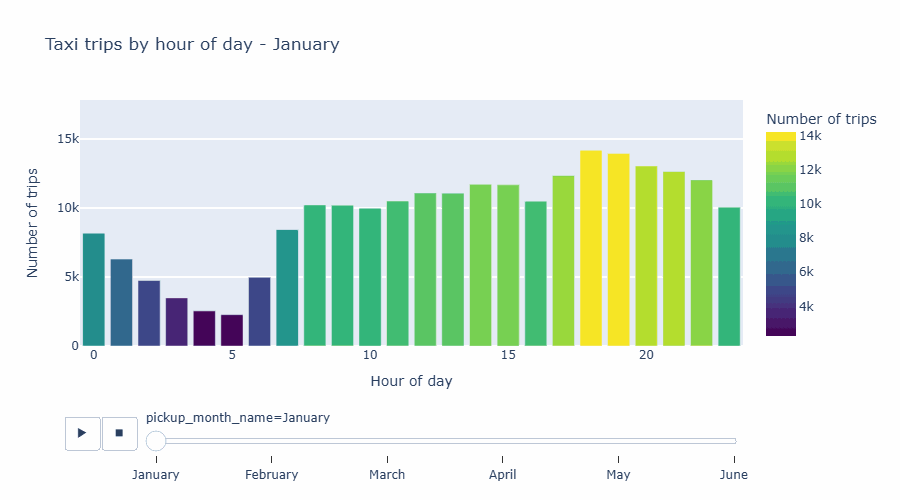

In [34]:
GIF_PATH = "outputs/trips_over_time.gif"
FRAME_MS = 900                       # time each frame stays on screen (milliseconds)

def save_gif(images, path, frame_ms):
    # images: list of PIL images -> animated GIF that loops forever
    images[0].save(path, save_all=True, append_images=images[1:], duration=frame_ms, loop=0)

# ---- Option 1: Plotly frames -> PNG pictures (Kaleido) ----
def gif_with_plotly(fig, path):
    pictures = []
    for frame in fig.frames:
        single = go.Figure(data=frame.data, layout=fig.layout)
        single.update_layout(updatemenus=[], sliders=[],
                             title="Taxi trips by hour of day - " + str(frame.name))
        png = single.to_image(format="png", width=900, height=500)
        pictures.append(Image.open(io.BytesIO(png)).convert("P", palette=Image.ADAPTIVE))
    save_gif(pictures, path, FRAME_MS)

# ---- Option 2: same frames drawn with matplotlib ----
def gif_with_matplotlib(table, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    y_max = table["trips"].max() * 1.1
    pictures = []
    for month_name, part in table.groupby("pickup_month_name", sort=False):
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.bar(part["pickup_hour"], part["trips"], color="#2a9d8f")
        ax.set_ylim(0, y_max)
        ax.set_xlabel("Hour of day")
        ax.set_ylabel("Number of trips")
        ax.set_title("Taxi trips by hour of day - " + month_name)
        fig.tight_layout()
        fig.canvas.draw()
        rgba = np.asarray(fig.canvas.buffer_rgba())
        pictures.append(Image.fromarray(rgba).convert("RGB").convert("P", palette=Image.ADAPTIVE))
        plt.close(fig)
    save_gif(pictures, path, FRAME_MS)

try:
    gif_with_plotly(fig_anim, GIF_PATH)
    print("GIF saved with Plotly + Kaleido ->", GIF_PATH)
except Exception as error:
    print("Plotly image export is not available here (Kaleido needs Chrome).")
    print("Using the matplotlib backup instead. Reason:", str(error).strip().splitlines()[0][:120])
    gif_with_matplotlib(monthly_hourly, GIF_PATH)
    print("GIF saved with matplotlib ->", GIF_PATH)

display(IPImage(filename=GIF_PATH))

## Step 8: Save the processed dataset and write the insights

In [35]:
import gc
gc.collect()                          # memory thodi khali karo

# df ki copy banaye bina seedha file me likhte hain
save_cols = [c for c in df.columns if c != "duration_calc"]

df.to_csv("nyc_taxi_processed.csv", index=False, columns=save_cols,
          float_format="%.5f", chunksize=100000)

df.sample(n=min(100000, len(df)), random_state=42).to_csv(
    "nyc_taxi_processed_sample.csv", index=False, columns=save_cols,
    float_format="%.5f")

print("Saved nyc_taxi_processed.csv        :", (len(df), len(save_cols)))
print("Saved nyc_taxi_processed_sample.csv :", min(100000, len(df)), "rows")

Saved nyc_taxi_processed.csv        : (1438277, 42)
Saved nyc_taxi_processed_sample.csv : 100000 rows


### Insights (calculated from the data)

In [36]:
# --- Numbers for the insights ---
hourly_trips = df.groupby("pickup_hour").size()
hourly_speed = df.groupby("pickup_hour")["speed_kmh"].mean()
weekday_trips = df["pickup_weekday"].value_counts()
month_trips = df.groupby(["pickup_month", "pickup_month_name"]).size()
group_share = df["passenger_group"].value_counts(normalize=True) * 100
tod_share = df["time_of_day"].value_counts(normalize=True) * 100
dist_share = df["distance_category"].value_counts(normalize=True) * 100

busiest_hour, quietest_hour = int(hourly_trips.idxmax()), int(hourly_trips.idxmin())
fastest_hour, slowest_hour = int(hourly_speed.idxmax()), int(hourly_speed.idxmin())
busiest_day = weekday_trips.idxmax()
quietest_day = weekday_trips.idxmin()
busiest_month = month_trips.idxmax()[1]
weekend_share = df["is_weekend"].mean() * 100
rush_speed = df.loc[df["is_rush_hour"] == 1, "speed_kmh"].mean()
offpeak_speed = df.loc[df["is_rush_hour"] == 0, "speed_kmh"].mean()
corr_dist_dur = df["distance_km"].corr(df["trip_duration"])
weekday_dur = df.loc[df["is_weekend"] == 0, "duration_min"].mean()
weekend_dur = df.loc[df["is_weekend"] == 1, "duration_min"].mean()
vendor_share = df["vendor_id"].value_counts(normalize=True) * 100

print(f"Busiest hour: {busiest_hour}:00 | Quietest hour: {quietest_hour}:00")
print(f"Fastest average speed at {fastest_hour}:00 ({hourly_speed.max():.1f} km/h), slowest at {slowest_hour}:00 ({hourly_speed.min():.1f} km/h)")
print(f"Busiest weekday: {busiest_day} | Quietest weekday: {quietest_day}")
print(f"Busiest month: {busiest_month}")
print(f"Rush-hour speed: {rush_speed:.1f} km/h vs other times: {offpeak_speed:.1f} km/h")
print(f"Average duration weekday: {weekday_dur:.1f} min vs weekend: {weekend_dur:.1f} min")
print(f"Correlation between distance and duration: {corr_dist_dur:.2f}")
print()
print(group_share.round(1).to_string())

Busiest hour: 18:00 | Quietest hour: 5:00
Fastest average speed at 5:00 (24.6 km/h), slowest at 15:00 (12.1 km/h)
Busiest weekday: Friday | Quietest weekday: Monday
Busiest month: March
Rush-hour speed: 12.6 km/h vs other times: 15.2 km/h
Average duration weekday: 14.4 min vs weekend: 12.9 min
Correlation between distance and duration: 0.78

passenger_group
Solo                 70.8
Couple               14.4
Large Group (5-6)     8.7
Small Group (3-4)     6.1


### Final report
The next cell writes `NYC_Taxi_Final_Report.md` automatically. It uses the real numbers calculated above, so the report always matches the data.

In [37]:
mean_dist, mean_dur, mean_speed = df["distance_km"].mean(), df["duration_min"].mean(), df["speed_kmh"].mean()
log_rows = "\n".join(f"| {name} | {removed:,} | {left:,} |" for name, removed, left in cleaning_log)
top_group = group_share.idxmax()
top_tod = tod_share.idxmax()
top_dist = dist_share.idxmax()
speed_gap = (offpeak_speed - rush_speed) / offpeak_speed * 100
gap_word = "slower" if speed_gap >= 0 else "faster"
rush_advice = (f"- Plan fares and driver schedules around rush hours, because trips are {abs(speed_gap):.0f}% slower then."
               if speed_gap > 1 else
               "- Rush hour does not change the average speed much in this data, so schedules can follow the demand pattern (busiest hours) instead.")

# Where do pickups happen? Share of pickups close to Times Square and to the two big airports
d_ts = haversine_km(df["pickup_latitude"], df["pickup_longitude"], 40.7580, -73.9855)
d_jfk = haversine_km(df["pickup_latitude"], df["pickup_longitude"], 40.6413, -73.7781)
d_lga = haversine_km(df["pickup_latitude"], df["pickup_longitude"], 40.7769, -73.8740)
share_ts = (d_ts <= 3).mean() * 100
share_airports = ((d_jfk <= 2) | (d_lga <= 2)).mean() * 100

report = [
    "# NYC Taxi Data Analysis - Final Report",
    "",
    "## 1. Objective",
    "Clean and prepare the NYC taxi trip data, create new features, scale and encode it, and use interactive charts to find insights about when, where and how people travel by taxi.",
    "",
    "## 2. Dataset",
    f"- Source: Kaggle - NYC Taxi Trip Duration (yasserh)",
    f"- Raw size: {rows_raw:,} trips",
    f"- Period covered: {df['pickup_datetime'].min():%d %b %Y} to {df['pickup_datetime'].max():%d %b %Y}",
    f"- Clean size: {len(df):,} trips ({len(df) / rows_raw:.1%} of the raw data kept)",
    "",
    "## 3. Data cleaning",
    "| Step | Rows removed | Rows left |",
    "|---|---|---|",
    log_rows,
    "",
    "Why: zero-length trips, impossible speeds, GPS points outside New York and unrealistic passenger counts are data errors. Keeping them would distort every average and chart.",
    "",
    "## 4. Feature engineering",
    "- Time features: hour, day, month, weekday, weekend flag, rush-hour flag, time of day",
    "- Distance (Haversine formula), trip duration in minutes, average speed (km/h)",
    "- Categories: distance category (Short/Medium/Long/Very Long) and passenger group (Solo/Couple/Small/Large)",
    "",
    "## 5. Scaling and encoding",
    "- Min-Max scaling puts values between 0 and 1; Standardization centres them at 0 with a standard deviation of 1. The shape of the data stays the same in both cases.",
    "- Min-Max is sensitive to outliers (a few long trips squeeze everyone else near 0); Standardization handles them better.",
    "- Label encoding was used for passenger group, time of day and the store-and-forward flag. One-hot encoding was used for passenger group and time of day.",
    "",
    "## 6. Key insights",
    f"1. **Typical trip:** about {mean_dist:.1f} km, {mean_dur:.1f} minutes, at {mean_speed:.1f} km/h on average. Most trips ({dist_share[top_dist]:.0f}%) are in the '{top_dist}' category.",
    f"2. **Demand peaks at {busiest_hour}:00** and is lowest at {quietest_hour}:00.",
    f"3. **Busiest weekday is {busiest_day}**, quietest is {quietest_day}. Weekends make up {weekend_share:.0f}% of trips.",
    f"4. **Busiest month is {busiest_month}.**",
    f"5. **Speed and traffic:** rush-hour speed is {rush_speed:.1f} km/h against {offpeak_speed:.1f} km/h at other times ({abs(speed_gap):.0f}% {gap_word}). The fastest hour is {fastest_hour}:00 ({hourly_speed.max():.1f} km/h) and the slowest is {slowest_hour}:00 ({hourly_speed.min():.1f} km/h).",
    f"6. **Who rides:** '{top_group}' is the largest passenger group ({group_share[top_group]:.0f}% of trips). '{top_tod}' is the most common time of day ({tod_share[top_tod]:.0f}% of trips).",
    f"7. **Distance vs duration:** correlation is {corr_dist_dur:.2f}, so longer trips take more time, but traffic makes duration less predictable than distance alone.",
    f"8. **Weekday vs weekend:** average trip lasts {weekday_dur:.1f} min on weekdays and {weekend_dur:.1f} min on weekends.",
    f"9. **Map view:** {share_ts:.0f}% of all pickups are within 3 km of Times Square, while {share_airports:.0f}% are within 2 km of JFK or LaGuardia airport (see the geo map and density map).",
    "",
    "## 7. Business recommendations",
    f"- Put more taxis on the road around {busiest_hour}:00 and on {busiest_day}s, and fewer around {quietest_hour}:00 to reduce idle time.",
    rush_advice,
    f"- Keep cars near the busiest pickup zones shown on the density map ({share_ts:.0f}% of pickups are within 3 km of Times Square) and check airport coverage ({share_airports:.0f}% of pickups are within 2 km of JFK or LaGuardia).",
    "- Use the passenger group and time-of-day patterns for targeted offers (for example larger vehicles for group trips).",
    "",
    "## 8. Limitations",
    "- Cleaning thresholds (1 minute to 3 hours, 1 to 100 km/h, 0.1 km minimum distance) are reasonable choices, not official rules; other thresholds would change the numbers slightly.",
    "- Haversine gives the straight-line distance, not the real road distance, so real trips are somewhat longer.",
    "- The map charts use a random sample of 20,000 trips for speed.",
    "",
    "## 9. Files produced",
    "- `nyc_taxi_processed.csv` and `nyc_taxi_processed_sample.csv`",
    "- `outputs/` folder: geo map, density map, animations, sunburst, scaling comparison and `trips_over_time.gif`",
]

with open("NYC_Taxi_Final_Report.md", "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("\n".join(report))

# NYC Taxi Data Analysis - Final Report

## 1. Objective
Clean and prepare the NYC taxi trip data, create new features, scale and encode it, and use interactive charts to find insights about when, where and how people travel by taxi.

## 2. Dataset
- Source: Kaggle - NYC Taxi Trip Duration (yasserh)
- Raw size: 1,458,644 trips
- Period covered: 01 Jan 2016 to 30 Jun 2016
- Clean size: 1,438,277 trips (98.6% of the raw data kept)

## 3. Data cleaning
| Step | Rows removed | Rows left |
|---|---|---|
| Missing critical values | 0 | 1,458,644 |
| Duplicates | 0 | 1,458,644 |
| Unreadable dates | 0 | 1,458,644 |
| Invalid duration (<1 min, zero/negative or >3 h) | 10,707 | 1,447,937 |
| Invalid passenger count (not 1-6) | 19 | 1,447,918 |
| Coordinates outside NYC area | 855 | 1,447,063 |
| Zero distance (<0.1 km) | 7,445 | 1,439,618 |
| Impossible speed (<1 or >100 km/h) | 1,341 | 1,438,277 |

Why: zero-length trips, impossible speeds, GPS points outside New York and unrealistic passenger